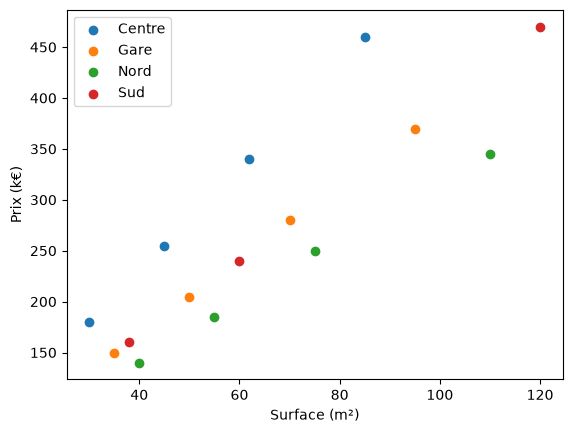

In [8]:
import pandas as pd 
import matplotlib.pyplot as plt 

df = pd.read_csv("appartements_propre.csv")

fig, ax = plt.subplots()
for quartier, groupe in df.groupby("quartier"):
    ax.scatter(groupe["surface"], groupe["prix"], label=quartier)
ax.set_xlabel("Surface (m²)")
ax.set_ylabel("Prix (k€)")
ax.legend()
plt.show()

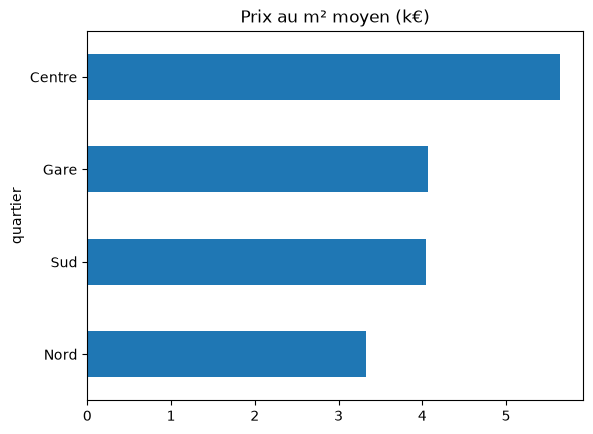

In [9]:
(df.groupby("quartier")["prix_m2"].mean()
    .sort_values()
    .plot.barh(title="Prix au m² moyen (k€)"))
plt.show()

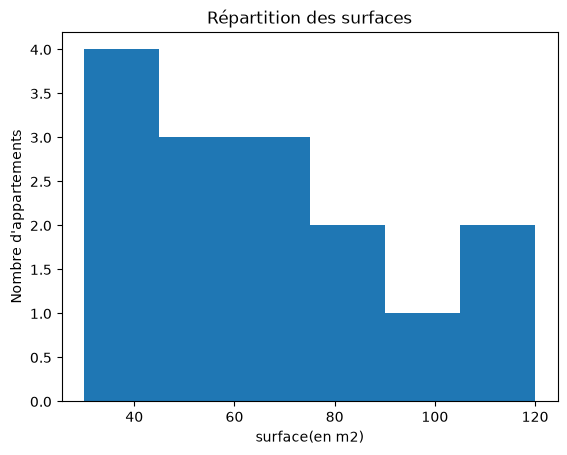

In [11]:
df["surface"].plot.hist(bins=6)
plt.title("Répartition des surfaces")
plt.xlabel("surface(en m2)")
plt.ylabel("Nombre d'appartements")
plt.show()

<Axes: xlabel='quartier'>

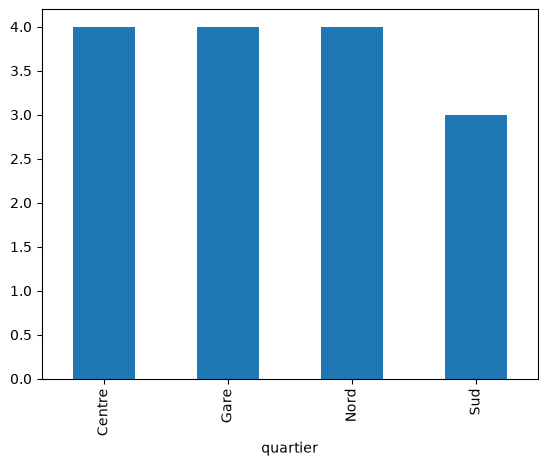

In [13]:
df.groupby("quartier")["id"].count().plot.bar()

<Axes: title={'center': 'Appartements par quartier'}, xlabel='quartier'>

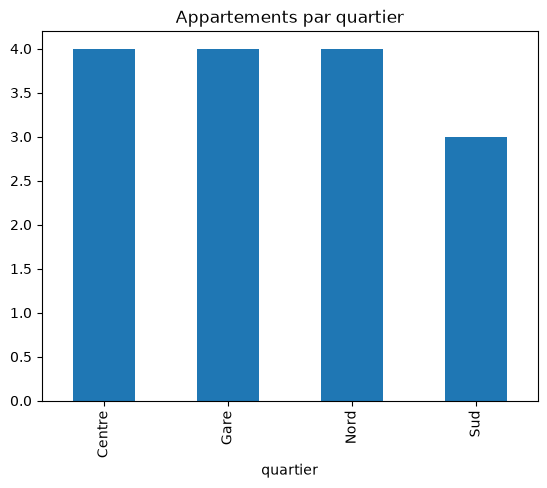

In [15]:
df["quartier"].value_counts().plot.bar(title="Appartements par quartier")

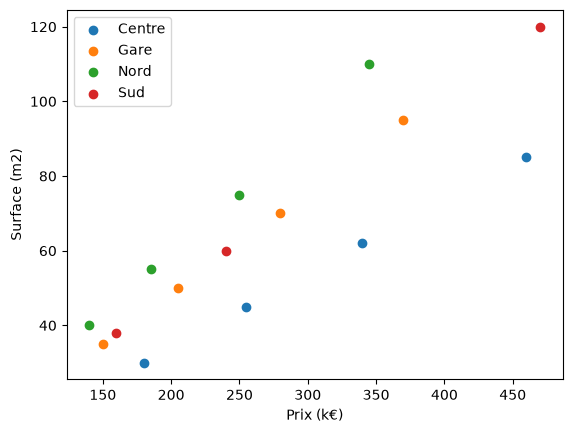

In [17]:

fig, ax = plt.subplots()
for quartier, groupe in df.groupby("quartier"):
    ax.scatter(groupe["prix"], groupe["surface"], label = quartier)
ax.set_xlabel("Prix (k€)")
ax.set_ylabel("Surface (m2)")
ax.legend()
plt.savefig("nuage.png", dpi=150)

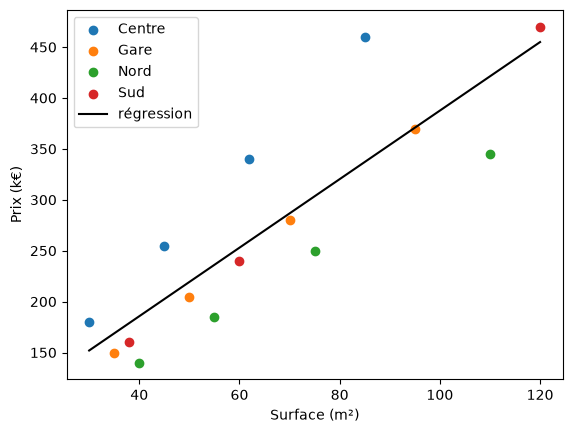

    id quartier  surface   prix  ecart
3    4   Centre       85  460.0  122.9
2    3   Centre       62  340.0   80.3
1    2   Centre       45  255.0   52.5
0    1   Centre       30  180.0   28.0
14  16      Sud      120  470.0   15.1
7    8     Gare       95  370.0   -0.8
6    7     Gare       70  280.0   -6.6
13  14      Sud       60  240.0  -13.0
5    6     Gare       50  205.0  -14.3
4    5     Gare       35  150.0  -18.8
12  13      Sud       38  160.0  -18.9
8    9     Nord       40  140.0  -45.6
9   10     Nord       55  185.0  -51.1
10  11     Nord       75  250.0  -53.4
11  12     Nord      110  345.0  -76.3


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("appartements_propre.csv")

# 1. Calculer la droite de régression
a, b = np.polyfit(df["surface"], df["prix"], 1)

# 2. Les points, colorés par quartier
fig, ax = plt.subplots()
for quartier, groupe in df.groupby("quartier"):
    ax.scatter(groupe["surface"], groupe["prix"], label=quartier)

# 3. La droite
x = np.array([df["surface"].min(), df["surface"].max()])
ax.plot(x, a * x + b, color="black", label="régression")

ax.set_xlabel("Surface (m²)")
ax.set_ylabel("Prix (k€)")
ax.legend()
plt.show()

# 4. Qui est le plus au-dessus de la droite ?
df["ecart"] = df["prix"] - (a * df["surface"] + b)
print(df.sort_values("ecart", ascending=False)[["id", "quartier", "surface", "prix", "ecart"]].round(1))